# Assignment 09: Gradient Forest and Genomic Turnover

## BIO597 Spatial Analysis of Biodiversity

Repeat the [Lab09](../labs/Lab09-GradientForest.ipynb) workflow for a snake species other than *P. guttatus*. Use SNP genotypes and climate predictors to investigate where modeled genetic turnover occurs along environmental gradients. You may reuse code from the lab.

## Deliverable

Submit this completed notebook with sample maps, SNP diagnostics, predictor importance, turnover curves, an aggregate PCA map/biplot, a single-SNP map/biplot, and short written answers. Save your diagnostic tables, transformed sample coordinates, curves, figures, and a GeoTIFF with one named band per predictor. Use the lab's filtering and model settings; no parameter search, additional algorithm, or future-climate projection is required.


## Install pyGF

Because this notebook environment is a bit wonky you need to redo this install every time you run a new notebook process.

The `pyGF` package is only available in my github repo, so the installation will need to be
'by hand'.

* Open a new terminal and `cd ~` to go to your home directory
* You should already have cloned the pygf repo so you don't need to do this again (but if you need to the command is `git clone https://github.com/isaacovercast/pygf.git`)
* `pip install -e pygf` to install this package and all requirements
* Restart the kernel for this notebook w/ the 'circle arrow' button in the notebook toolbar
* Now you should be able to do the imports in the next cell

## 1. Import packages and set up paths

Run this notebook from `docs/assignments` using the same Python environment as Lab09, with `pygf` and its notebook dependencies installed. The imports and JupyterHub paths are provided below.

The assignment's genetic data are in **`/home/jovyan/shared/EasternSnakeGenetics`**. The climate layers use the same **`/home/jovyan/shared-readwrite/bioclim`** directory as Lab09. Keep all input paths in these two variables so later calls use the same files. Save your results in your own repository, not in a shared input directory.

For local work, the genetic files are in `../labs/EasternSnakes`; you must also point `bioclim_dir` to a local directory containing the 19 regional bioclim rasters. The Maine-only climate layers from earlier labs do not cover these samples.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pygf import GradientForest, read_coordinates, read_vcf, sample_environment

genetics_dir = Path("/home/jovyan/shared/EasternSnakeGenetics")
bioclim_dir = Path("/home/jovyan/shared/bioclim")


## 2. Choose another snake species

Choose one of the three species with both a VCF and a headerless coordinate file. Use the **file stem** exactly as shown; do not choose the lab's `Pguttatus`.

| File stem | Species | Genetic files |
| --- | --- | --- |
| `Acontortrix` | *Agkistrodon contortrix* | `Acontortrix.vcf`, `Acontortrix_coords.txt` |
| `Lgetula` | *Lampropeltis getula* | `Lgetula.vcf`, `Lgetula_coords.txt` |
| `Sdekayi` | *Storeria dekayi* | `Sdekayi.vcf`, `Sdekayi_coords.txt` |

The `.txt` coordinate files contain sample ID, longitude, and latitude **without a header**, as expected by `read_coordinates()`. Use these files rather than the similarly named `.csv` tables.


In [2]:
target_species = "Lgetula"

species_names = {
    "Acontortrix": "Agkistrodon contortrix",
    "Lgetula": "Lampropeltis getula",
    "Sdekayi": "Storeria dekayi",
}
assert target_species in species_names, "Choose one of the three file stems above."

species_name = species_names[target_species]
vcf_path = genetics_dir / f"{target_species}.vcf"
coords_path = genetics_dir / f"{target_species}_coords.txt"
assert vcf_path.is_file(), f"VCF not found: {vcf_path}"
assert coords_path.is_file(), f"Coordinates not found: {coords_path}"

output_dir = Path("Assignment09_outputs") / target_species
output_dir.mkdir(parents=True, exist_ok=True)
print(species_name)
print(vcf_path)
print(coords_path)


Lampropeltis getula
/home/jovyan/shared/EasternSnakeGenetics/Lgetula.vcf
/home/jovyan/shared/EasternSnakeGenetics/Lgetula_coords.txt


**Why this species?** Give one biological reason for your choice.

*Your answer:*  Lampropeltis Getula is the common kingsnake. I picked the the kingsnake because it appears that in the southern united states it has a very broad habitat range and exhists in many differnt environments. 

## 3. Read coordinates and filtered genotypes

Read `coords_path` into `sites` with `read_coordinates()`. Read `vcf_path` into `genotypes` with `read_vcf()`, passing `samples=sites` so genotype rows follow coordinate-file order. Keep the lab settings:

- `min_call_rate=0.8`
- `min_maf=0.05`
- `one_per_contig=True`
- `max_variants=256`
- `random_state=42`

Display the number of individuals and retained SNPs. Map the sample locations with a title naming your species. These points describe sampling, not the species' entire range.


(36, 256)


Text(0.5, 1.0, 'Lampropeltis getula')

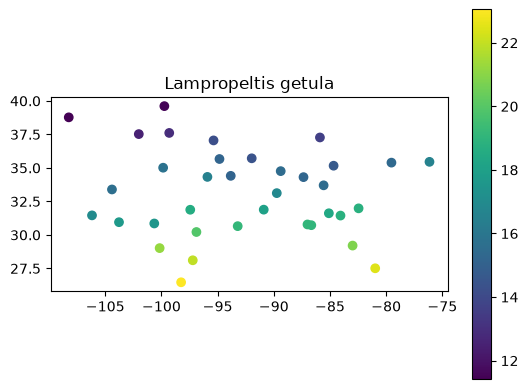

In [3]:
# Read coordinates as sites.

sites = read_coordinates("/home/jovyan/shared/EasternSnakeGenetics/Pguttatus_coords.txt")

# Read the VCF as genotypes, using samples=sites and all five settings above.

genotypes = read_vcf(
    "/home/jovyan/shared/EasternSnakeGenetics/Pguttatus.vcf",
    samples=sites,
    min_call_rate=0.8,
    min_maf=0.05,
    one_per_contig=True,
    max_variants=256,
    random_state=42,
)


# Use genotypes.dosage.to_pandas().shape to inspect individuals × SNPs.

print(genotypes.dosage.to_pandas().shape)
# Print the dimensions and plot sites with a species title.
X = sample_environment("/home/jovyan/shared/bioclim", sites)
y = genotypes.dosage.to_pandas()
sites.plot(column=X.bio1, legend=True).set_title("Lampropeltis getula")



**Interpretation:**

1. What do dosage values 0, 1, and 2 represent? How does a missing call differ from a zero?
The dosage values are the number of alternate allele at a SNP. a missing call is different then a zero because a zero means there are no alternates but a a missing call means there is no data. 
2. What do call rate and minor allele frequency filter out? Why might the chosen SNP subset affect your conclusions?

Call rate filters out SNP's with not enough data and minor allele frequency filters out SNP's that have extremely rare occurences of less common alleles. This can have an effect on how much genetic variation is included. 

3. Why does taking one SNP per RAD contig reduce repeated local information without guaranteeing independent loci?

it reduces this because SNPS on the same contig are next to each other. it doesnt guarantee independce though because they could still be close together in the whole genome regardless. 
*Your answers:* 

## 4. Sample climate and align individuals

Extract all 19 climate variables at the sample locations. The provided code removes rows with missing climate and aligns all three inputs to the same IDs. Missing genotypes remain `NaN`; each SNP's forest uses its observed calls. Do not replace missing genotypes with zeros.

`sample_environment()` reprojects points to the raster CRS and samples raster values at those locations. It also remembers the source directory and sampling region for mapping.


In [4]:
n_before = len(sites)
X = sample_environment(bioclim_dir, sites, drop_missing=True)
y = genotypes.dosage.to_pandas().loc[X.index]
sites = sites.loc[X.index].copy()

assert sites.index.equals(X.index)
assert X.index.equals(y.index)
assert np.isfinite(X.to_numpy()).all()
assert X.shape[1] == 19, "Use the full regional bioclim stack."

print("Individuals before climate extraction:", n_before)
print("Individuals with complete climate:", len(X))
print("Climate predictors:", X.shape[1])
print("Filtered SNPs:", y.shape[1])
X.head()


Individuals before climate extraction: 36
Individuals with complete climate: 36
Climate predictors: 19
Filtered SNPs: 256


,bio1,bio2,bio3,bio4,bio5,bio6,bio7,bio8,bio9,bio10,bio11,bio12,bio13,bio14,bio15,bio16,bio17,bio18,bio19
sample,,,,,,,,,,,,,,,,,,,
LSU99213,19.115833,11.865000,40.417633,676.937683,33.139999,3.784,29.355999,11.547334,15.234667,27.132000,10.488000,1478.0,158.0,92.0,14.483758,418.0,320.0,366.0,405.0
OMNH9224,15.792167,15.137000,37.766968,913.650269,35.743999,-4.336,40.079998,20.497334,4.397333,26.977333,4.397333,626.0,104.0,17.0,52.633015,247.0,62.0,198.0,62.0
OMNH8361,15.129333,12.856667,37.627800,792.639038,32.000000,-2.168,34.167999,14.956667,5.099333,24.677999,5.099333,1509.0,169.0,86.0,19.535410,470.0,323.0,337.0,323.0
FLMNH153506,18.062166,13.024334,41.315613,711.381104,33.180000,1.656,31.524000,10.619333,23.122667,26.576666,9.070666,1488.0,162.0,88.0,20.799999,443.0,273.0,307.0,430.0
FLMNH151609,15.625667,17.631334,44.424850,837.177002,35.023998,-4.664,39.688000,25.017332,7.156667,25.798000,5.204000,332.0,62.0,8.0,66.924088,162.0,27.0,151.0,32.0


variant      RAD_339:16:G:A  RAD_675:24:G:A  RAD_694:75:C:T  RAD_1075:37:T:C  \
sample                                                                         
LSU99213                NaN             0.0             0.0              0.0   
OMNH9224                1.0             0.0             2.0              NaN   
OMNH8361                0.0             0.0             0.0              0.0   
FLMNH153506             0.0             2.0             NaN              NaN   
FLMNH151609             0.0             0.0             0.0              0.0   

variant      RAD_1107:29:A:G  RAD_1252:11:C:T  RAD_1453:15:C:T  \
sample                                                           
LSU99213                 0.0              0.0              0.0   
OMNH9224                 0.0              0.0              0.0   
OMNH8361                 0.0              NaN              0.0   
FLMNH153506              NaN              2.0              NaN   
FLMNH151609              NaN              0

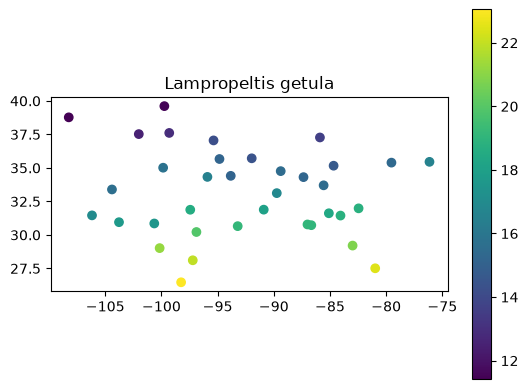

In [5]:
# Map sites colored by X["bio1"] with a legend and species title.
sites.plot(column=X.bio1, legend=True).set_title("Lampropeltis getula")

# Inspect y.head() to confirm that SNPs are columns and individuals are rows.
print(y.head())


**Interpretation:** Were any individuals removed for missing climate? Why must `sites`, `X`, and `y` retain the same IDs and row order? Explain why these responses are individual genotypes rather than population allele frequencies.

*Your answer:* No, no individuals were removed. making sure x,y and sites have the same id a raw ensures environemntal and genetic data stay correctly matches up. this data is from individuals and not from complete populations. 
## 5. Fit SNP-specific forests

Create `gf = GradientForest(...)` using `n_estimators=100`, `max_level=2`, `random_state=42`, and `keep_response_curves=True`, then fit it with `X` and `y`.

These settings match the lab. `max_level=2` controls approximate conditional permutations for correlated predictors; it does not limit tree depth. Retaining response curves lets us inspect one SNP later.


In [9]:
# Create gf with the four settings above and fit it to X and y.
gf = GradientForest(
    n_estimators=100, max_level=2, random_state=42, keep_response_curves=True,
).fit(X, y)

# Display gf.response_scores_ sorted by descending oob_r2.
print(gf.response_scores_.sort_values("oob_r2", ascending=False).head())

                  n_observed    oob_r2  oob_coverage  retained    reason
response                                                                
RAD_11467:26:C:A          33  0.817141           1.0      True  retained
RAD_49550:52:C:T          30  0.780227           1.0      True  retained
RAD_44571:22:A:G          30  0.756812           1.0      True  retained
RAD_42610:36:G:T          29  0.742778           1.0      True  retained
RAD_18759:57:T:C          31  0.732192           1.0      True  retained


## 6. Inspect OOB skill and contributing SNPs

Use `gf.response_scores_` to report the number of SNPs evaluated, the number contributing to turnover (`retained=True`), and the fraction contributing. Display the counts of each `reason`, and plot the distribution of `oob_r2` values with a vertical line at zero.

Only SNPs with positive OOB R² and positive permutation importance contribute. Include excluded SNPs in your diagnostic summary, not just the best-scoring ones. If no SNPs contribute, report that outcome and consult the instructor before changing filters or model settings.


256
256
1.0


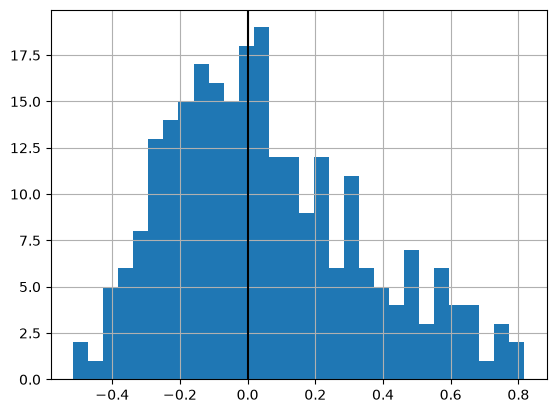

In [10]:
# Store gf.response_scores_ as scores.
scores = gf.response_scores_

# Print evaluated and retained counts and the retained fraction.

print(len(scores))
print(len(scores["retained"] == True))
print(len(scores)/len(scores["retained"] == True))
# Display scores["reason"].value_counts().
scores["reason"].value_counts()

# Plot scores["oob_r2"].dropna() as a histogram, with a reference line at zero.
scores["oob_r2"].dropna().hist(bins=30)
plt.axvline(x=0, color = "black")

**Interpretation:** What does an OOB R² below zero mean? Why does a positive OOB score not establish either adaptation or accurate prediction in a new geographic region?

*Your answer:* an oob R-squared below 0 means the model does worse then the mean for those SNPS. It does not estabilish adaption or accurate prediction because it could be a relic of population structure or sampling error. 

## 7. Rank environmental predictors

Plot `gf.importance_` as a horizontal bar chart, as in the lab. Label the axis **Mean allocated OOB R²**. Identify your top three predictors and look up their meanings in the [WorldClim variable definitions](https://www.worldclim.org/data/bioclim.html).

These values average allocated skill over contributing SNPs. They are not percentages of adaptive variation and need not sum to one.


Importance of Precipitation of Coldest Quarter: 0.04396863658217548
Importance of Precipitation of Warmest Quarter 0.032269324346925046
Importance of Annual Precipitation 0.029474313331338594


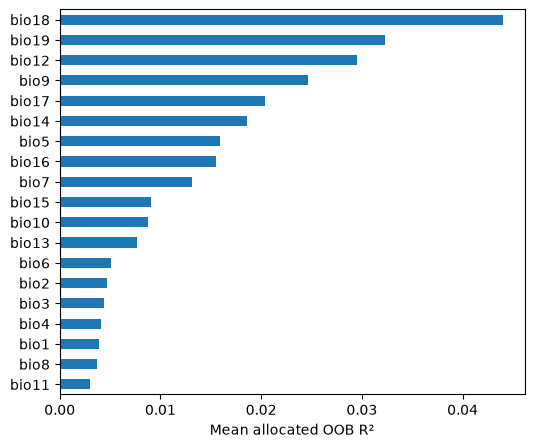

In [11]:
# Make a labeled horizontal bar plot of gf.importance_.

gf.importance_.sort_values().plot.barh(figsize=(6, 5), xlabel="Mean allocated OOB R²");

# Display the three highest-ranked predictors and their importance values.

print("Importance of Precipitation of Coldest Quarter:", gf.importance_["bio18"])
print("Importance of Precipitation of Warmest Quarter", gf.importance_["bio19"])
print("Importance of Annual Precipitation", gf.importance_["bio12"])


**Interpretation:** Name your top three climate variables. Suggest a biological explanation for one association, and one reason that predictor importance does not isolate a causal effect. How could correlation among the 19 climate predictors complicate the ranking?

*Your answer: Precipitation of Coldest Quarter, Precipitation of Warmest Quarter, Annual Precipitation. Annual precipitation may be associated with survival and reproduction so it could influence genetics. it does not issolate a causel effect because there may be other things beyond percipitation impacting the underlying genetic data. correleation might complicate the ranking because alot of the variables may be explaining very similar processes. It is therefor difficult to pick out which one is more important.


* 

## 8. Plot cumulative turnover curves

Run the lab's plotting recipe below to show the six leading predictors. Each x axis uses that predictor's environmental values; check the raster units or scaling before assigning physical units. Each endpoint equals the predictor's importance.


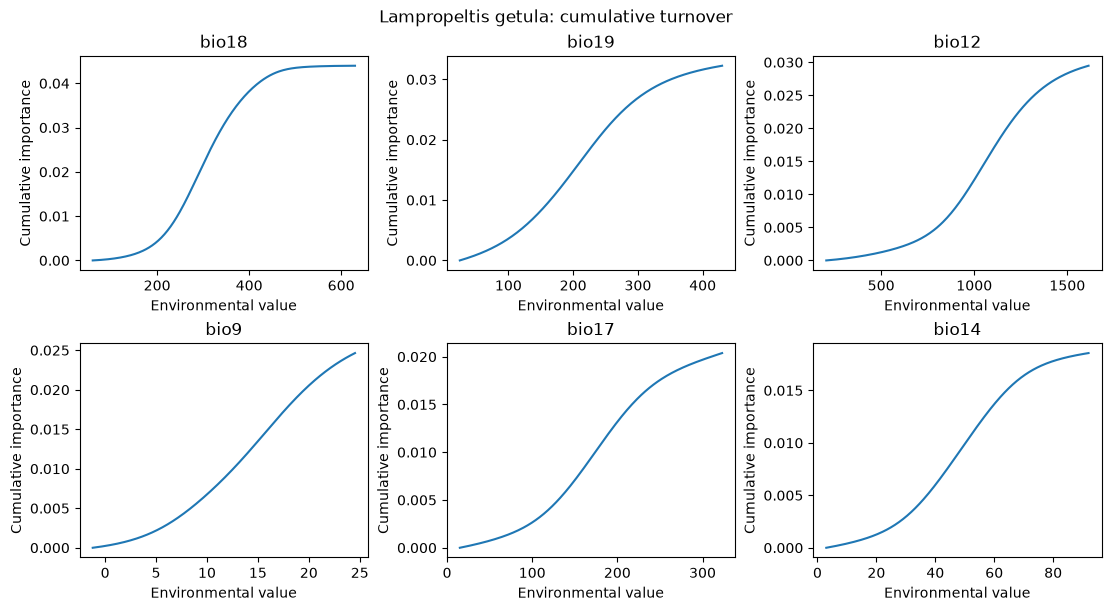

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), layout="constrained")
for ax, name in zip(axes.flat, gf.importance_.head(6).index):
    curve = gf.turnover_[name]
    ax.plot(curve.value, curve.cumulative_importance)
    ax.set(title=name, xlabel="Environmental value", ylabel="Cumulative importance")
fig.suptitle(f"{species_name}: cumulative turnover")
plt.show()
curves_figure = fig


**Interpretation:** Choose one curve and describe the environmental interval where it rises most rapidly, using approximate x-axis values. What does a high but flat section mean? Why can the cumulative curve increase even when some SNP dosages decrease along the gradient?

*Your answer: Bio 18 rises the most rapidly from 200-400. a high but flat section means it is important but it does not get any more important with an increasing environmental value. It is able to increase still because it measures cummulative increase.* 

## 9. Transform sampled environments and map a turnover layer

Use `gf.transform(X)` to create `turnover`, then display its first rows and dimensions. This returns one turnover coordinate per environmental predictor for each individual. In pyGF, `predict()` aliases `transform()`; it does not return predicted allele frequencies.

The map call below uses the leading predictor and the same regional bioclim directory. It samples every fourth raster cell in a region buffered 20% around the sites, as in the lab. Missing predictor pixels are masked; values beyond a fitted predictor range are clamped to its curve endpoint.


In [13]:
# Create turnover with gf.transform(X).
turnover = gf.transform(X)
# Display turnover.head() and turnover.shape.
turnover.head()
turnover.head()

,bio1,bio2,bio3,bio4,bio5,bio6,bio7,bio8,bio9,bio10,bio11,bio12,bio13,bio14,bio15,bio16,bio17,bio18,bio19
sample,,,,,,,,,,,,,,,,,,,
LSU99213,0.001192,0.000255,0.003208,0.000997,0.004935,0.003737,0.001119,0.000740,0.013844,0.002585,0.001675,0.028036,0.006532,0.018558,0.000000,0.012415,0.020291,0.033995,0.031751
OMNH9224,0.000460,0.003694,0.002432,0.003277,0.014760,0.001308,0.012559,0.002371,0.001814,0.002382,0.000660,0.002243,0.002262,0.000946,0.008034,0.002230,0.001066,0.004087,0.001414
OMNH8361,0.000379,0.000807,0.002378,0.001948,0.001496,0.002087,0.005761,0.001431,0.002236,0.000462,0.000753,0.028439,0.006946,0.018243,0.001003,0.014165,0.020379,0.029243,0.028561
FLMNH153506,0.000852,0.000922,0.003399,0.001277,0.005090,0.003180,0.002473,0.000560,0.023630,0.001951,0.001359,0.028172,0.006699,0.018359,0.001292,0.013379,0.018704,0.023228,0.032269
FLMNH151609,0.000439,0.004648,0.003923,0.002390,0.012758,0.001185,0.012393,0.003232,0.003816,0.001280,0.000767,0.000390,0.000274,0.000275,0.008721,0.000473,0.000227,0.001447,0.000231


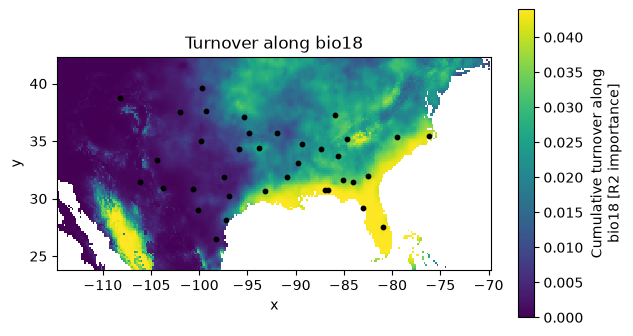

In [14]:
turnover_map = gf.plot_turnover(environment=bioclim_dir, points=sites)


**Interpretation:** Which predictor is mapped? Describe one geographic transition in its transformed values. Why is a high map value not necessarily a place with rapid local turnover? What happens outside the predictor's training range, and why does this limit interpretation?

*Your answer: bio18 is mapped. it appears that at the southern Gulf and atlantic coast it becomes very high. It does not predict local tournover because it just predicts cummulative turnover for that environmental gradiant. out side of the training range the model cannot predict so is at an edge value and this may result in incomplete modeling over the speices range. *

## 10. Make an aggregate spatial PCA biplot

Create `biplot` with `gf.plot_biplot(X, sites, environment=bioclim_dir, n_vectors=3)`. The map and ordination share colors from the first three PCs of the GF-transformed environments. PC1 and PC2 locate points in the biplot; PC1/2/3 supply the color channels.

The PCA uses transformed raster environments without standardizing columns to unit variance, preserving GF importance weights. Labelled arrows are environmental covariance loadings: direction indicates increasing transformed environmental values, and relative length indicates contribution to the displayed PC1/2 pattern.


,PC1,PC2,PC3,length,importance
bio18,0.011742,-0.002466,0.006140,0.011999,0.043969
bio19,0.010752,0.001121,-0.003123,0.010811,0.032269
bio12,0.009860,0.000095,-0.001022,0.009861,0.029474
bio9,0.002735,0.008264,0.000860,0.008705,0.024644
bio17,0.007132,-0.000166,-0.002565,0.007134,0.020379
bio14,0.006806,-0.000278,-0.002521,0.006811,0.018558
bio16,0.004361,0.000082,0.001610,0.004362,0.015494
bio5,-0.001975,0.003737,0.000799,0.004227,0.015876
bio7,-0.002172,-0.002493,-0.001198,0.003306,0.013164
bio15,-0.002495,0.000649,0.001952,0.002578,0.009044


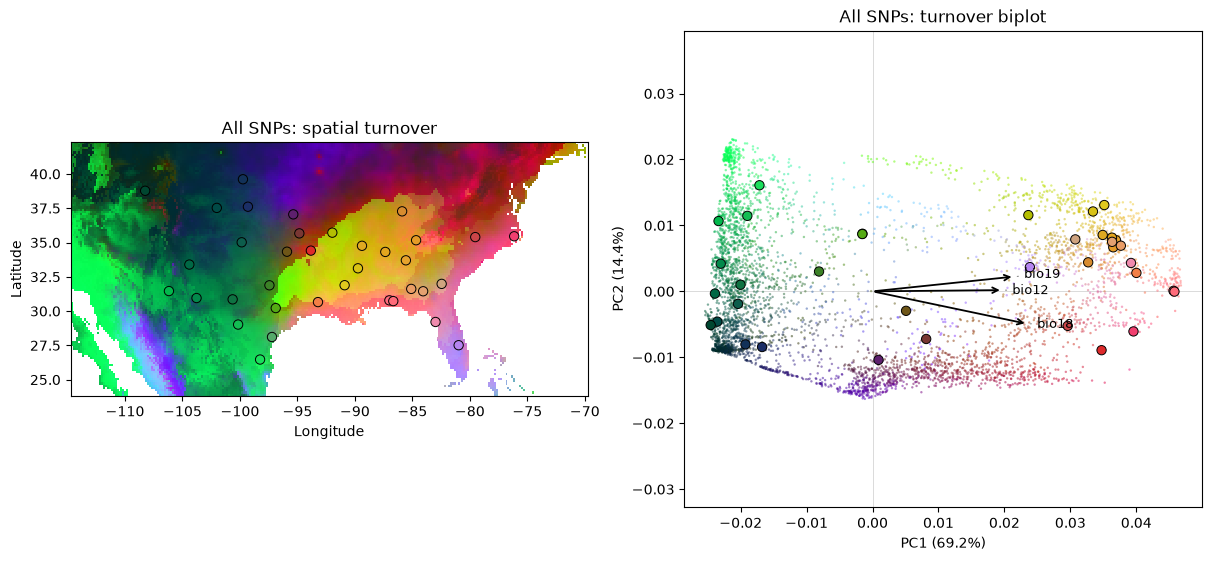

In [15]:
# Create biplot with the call above.
biplot = gf.plot_biplot(X, sites, environment="/home/jovyan/shared/bioclim", n_vectors=3)
# Display biplot.vectors to inspect the environmental arrows.
biplot.vectors

**Interpretation:** Describe the main geographic color transition and an environmental arrow associated with it. What does similarity in color summarize? Why do neither the colors nor the arrows measure fitness or prove local adaptation?

*Your answer: The mid east appears to turn reddish which seems to be associated with the bio18 variable. similar colors indicate similar genetics. color and arrow only show the associations wiht environmnetal variables. *

## 11. Compare with a single-SNP biplot

Select the highest-OOB-R² SNP among contributing responses using the provided code. Create `snp_biplot` with the same call as before, adding `response=snp`. Use **`environment=bioclim_dir` in both biplot calls**, rather than an upstream-relative `../envs` path.

Each response has its own PCA basis and color calibration. Compare geographic organization and arrows; matching colors across separate plots have no shared genetic meaning. Selecting the best-scoring SNP is an illustration, not independent validation or discovery of an adaptive locus.


Selected SNP: RAD_11467:26:C:A
n_observed            33
oob_r2          0.817141
oob_coverage         1.0
retained            True
reason          retained
Name: RAD_11467:26:C:A, dtype: object


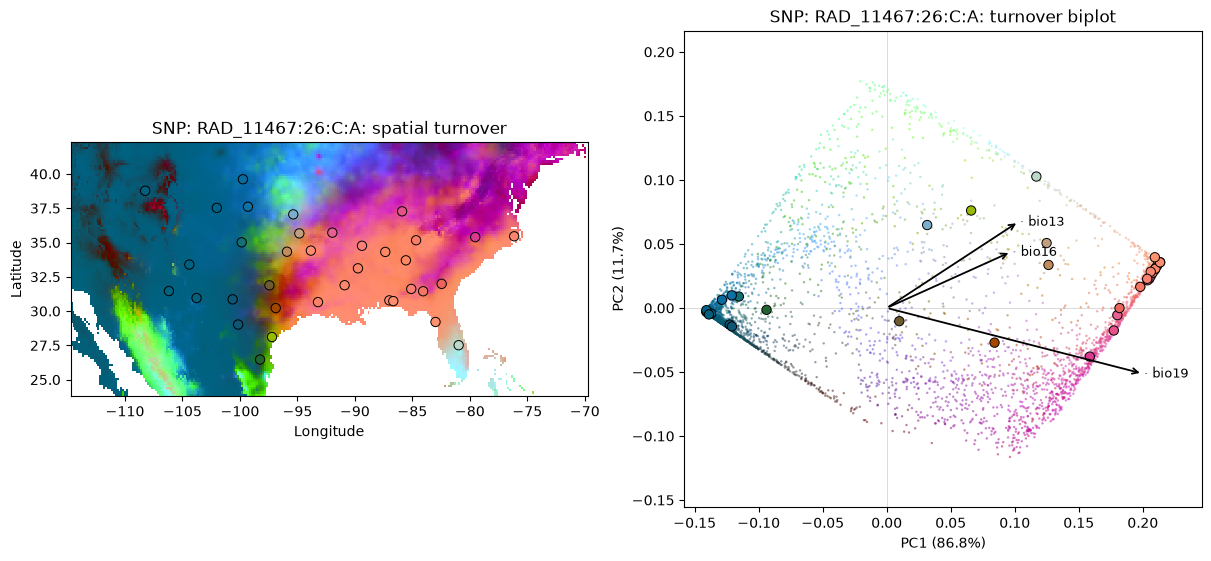

In [16]:
contributing_scores = gf.response_scores_.loc[gf.response_scores_["retained"]]
snp = contributing_scores["oob_r2"].idxmax()
print("Selected SNP:", snp)
print(contributing_scores.loc[snp])

# Create snp_biplot using gf.plot_biplot(), environment=bioclim_dir,
snp_biplot = gf.plot_biplot(X, sites, environment="/home/jovyan/shared/bioclim", response=snp, n_vectors=3)



**Interpretation:** How does this SNP's geographic pattern differ from the aggregate pattern? Can you interpret a red region in both plots as the same genetic composition? Explain.

*Your answer: There is no green in the south east while there is a green spot in the aggregate. there does appear to a reddish region in the east. Possibly the same genetic compostion in that region.*

## 12. Export your results

The export recipe below follows the lab. It saves outputs under `Assignment09_outputs/<your file stem>/`, keeping runs for different species separate. The GeoTIFF contains one named band per environmental predictor, not per SNP.

Run the cell after completing the earlier steps. Keep the sample IDs in exported tables and preserve the raster's CRS and NoData mask. The small summary records the species, data paths, filtering choices, and model settings used in this analysis.


In [17]:
gf.response_scores_.to_csv(output_dir / "snp_oob_scores.csv")
gf.importance_.to_csv(output_dir / "predictor_importance.csv")
turnover.to_csv(output_dir / "sample_turnover.csv")
sites[["longitude", "latitude"]].to_csv(output_dir / "sample_coordinates.csv")
pd.concat(gf.turnover_, names=["predictor", "bin"]).to_csv(output_dir / "turnover_curves.csv")

summary = pd.DataFrame([{
    "species": species_name,
    "file_stem": target_species,
    "vcf": str(vcf_path),
    "coordinates": str(coords_path),
    "bioclim_directory": str(bioclim_dir),
    "n_individuals": len(X),
    "n_predictors": X.shape[1],
    "n_snps": y.shape[1],
    "n_contributing": int(gf.response_scores_["retained"].sum()),
    "min_call_rate": 0.8,
    "min_maf": 0.05,
    "one_per_contig": True,
    "max_variants": 256,
    "n_estimators": 100,
    "max_level": 2,
    "random_state": 42,
}])
summary.to_csv(output_dir / "analysis_summary.csv", index=False)

bands = turnover_map.turnover.to_array("band").rio.write_nodata(np.nan)
bands.attrs["long_name"] = tuple(X.columns)
bands.rio.to_raster(output_dir / "genomic_turnover.tif", compress="deflate", dtype="float32")

curves_figure.savefig(output_dir / "turnover_curves.png", dpi=150, bbox_inches="tight")
turnover_map.figure.savefig(output_dir / "turnover_map.png", dpi=150, bbox_inches="tight")
biplot.figure.savefig(output_dir / "turnover_biplot.png", dpi=150, bbox_inches="tight")
snp_biplot.figure.savefig(output_dir / "snp_biplot.png", dpi=150, bbox_inches="tight")

print("Saved results to:", output_dir.resolve())
summary


Saved results to: /home/jovyan/BIO597-SpatialBiodiversity/docs/assignments/Assignment09_outputs/Lgetula


,species,file_stem,vcf,coordinates,bioclim_directory,n_individuals,n_predictors,n_snps,n_contributing,min_call_rate,min_maf,one_per_contig,max_variants,n_estimators,max_level,random_state
0,Lampropeltis getula,Lgetula,/home/jovyan/shared/EasternSnakeGenetics/Lgetu...,/home/jovyan/shared/EasternSnakeGenetics/Lgetu...,/home/jovyan/shared/bioclim,36,19,256,136,0.8,0.05,True,256,100,2,42


## Final reflection

Answer each question in two or three sentences, referring to your figures or diagnostic results.

1. How does this genotype-based analysis differ from the species presence/background SDMs in Labs07–08? Why is a turnover coordinate different from a suitability score or allele frequency?

SDMS use species presence to predict habitat suitability. This analysis uses SNP data to look at how genetic variation changes across the environment. One is looking at suitability while the other is looking at genetic variation. 
2. Which predictor and environmental interval showed a clear turnover pattern for your species? What evidence supports your description, and what sampling or modeling choice could change it?

The bio18 variable between 200 and 400. This is supported by the cumulative turnover curves. If you included samples in more variable environemtns the environmental interval pattern could change.  


3. Describe one alternative to local adaptation that could produce a genetic–environmental association. What additional data or analysis would help distinguish the explanations?
isolation could result in a gentic-enivronmental association just through random mutations that track through the isolated population. If you could analyze weather mutations are adaptive you could better get at answering these questions. 

4. What would you withhold to test prediction in a new region? Explain why OOB evaluation alone does not answer that question.
    
I would withhold all observations from that new region and tehn try to test using only the observations form the training data. OOD evalution alone does not answer that question because it only evaluates ob


*Your answers:*

## Submit your work

Restart the kernel and run the notebook from top to bottom after completing the code prompts. Check that your figures appear, written answers are filled in, diagnostic counts are reported, and all exports exist. Commit and push this notebook and your species' output folder to your class GitHub repository. The original VCF and climate rasters remain in shared storage and should not be included in your submission.

Run these Git commands **from the repository root**, replacing `YOUR_SPECIES` with your chosen file stem:

```bash
git add docs/assignments/Assignment-09-GradientForest.ipynb docs/assignments/Assignment09_outputs/YOUR_SPECIES/
git commit -m "Complete Gradient Forest assignment"
git push
```

## References

- [Lab09: Gradient Forest](../labs/Lab09-GradientForest.ipynb)
- [Lecture09: Gradient Forest and Genomic Turnover](../lectures/Lecture09-GradientForest.html)
- [pyGF implementation and interpretation notes](https://github.com/isaacovercast/pygf)
- [Ellis, Smith & Pitcher (2012): the original Gradient Forest method](https://doi.org/10.1890/11-0252.1)
- [WorldClim bioclimatic variable definitions](https://www.worldclim.org/data/bioclim.html)
